In [2]:
import sys
sys.path.append("/home/emgutierrez/Dropbox/edu_luc_collab/2022_jetjet_collision/astrograv_py/modules/")
import numpy as np
from constants_cgs import *
import matplotlib.pyplot as plt

In [15]:
M = 6.5e9
rg = gravConstant * M * solarMass / cLight2
z0_rg = 2.
z0 = z0_rg * rg
z_rg = np.geomspace(z0_rg, 10000, 200)
zVec = z_rg * rg
B0 = 10. # Gauss
Ub0 = B0*B0 / (8*np.pi)
Gamma0 = 1.1
GammaIndex = 0.2

a_inj = 0.3
zMax_inj = 500 * rg
Ljet = 1e42
eta_inj = 0.1
Linj = eta_inj*Ljet
rIndex = 0.5
r0 = z0

sigma0 = 3.
mu = Gamma0 * (1. + sigma0)
Mdot = Ljet / cLight2 / Gamma0 / (sigma0 + 1)
hp_zMax = 1. / (1.0 - eta_inj)
print(hp_zMax)

1.1111111111111112


In [4]:
def Gamma(z):
    result = Gamma0 * np.power(z/z0, GammaIndex)
    return np.where(result < mu/hp_zMax, result, mu/hp_zMax)

def sigma(z):
    return mu/Gamma(z)/hp(z) - 1.

def Li(z):
    return Gamma(z) * Mdot * cLight2

def Le_Lph(z):
    result = Linj * (1 - np.power(z0/zVec, a_inj)) / (1. - np.power(z0/zMax_inj, a_inj))
    return np.where(z < zMax_inj, result, Linj)

def beta(z):
    return np.sqrt(1.0-1.0/Gamma(z))

def r(z):
    return r0 * np.power(z/z0, rIndex)

def hp(z):
    return 1. + Le_Lph(z)/Li(z)

def Lb(z):
    result = mu - Gamma(z)*hp(z)
    return Mdot * cLight2 * np.where(result > 0., result, 0.)

def B(z):
    return 2./(Gamma(z)*r(z)) * np.sqrt(Mdot*cLight2 * (mu-Gamma(z)*hp(z)) / (beta(z)*cLight))

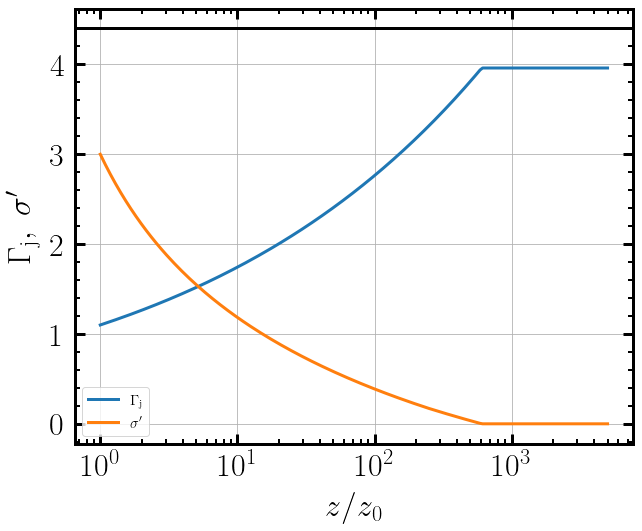

In [20]:
with plt.style.context(('publi')):
    
    fig, ax = plt.subplots()
    ax.set_xlabel(r'$z/z_0$')
    ax.set_ylabel(r"$\Gamma_{\rm j},~\sigma'$")
    
    ax.semilogx(z_rg/z0_rg, Gamma(zVec), label=r'$\Gamma_{\rm j}$')
    ax.semilogx(z_rg/z0_rg, sigma(zVec), label=r"$\sigma'$")
    ax.axhline(mu, color='k')

    ax.legend(fontsize=15)

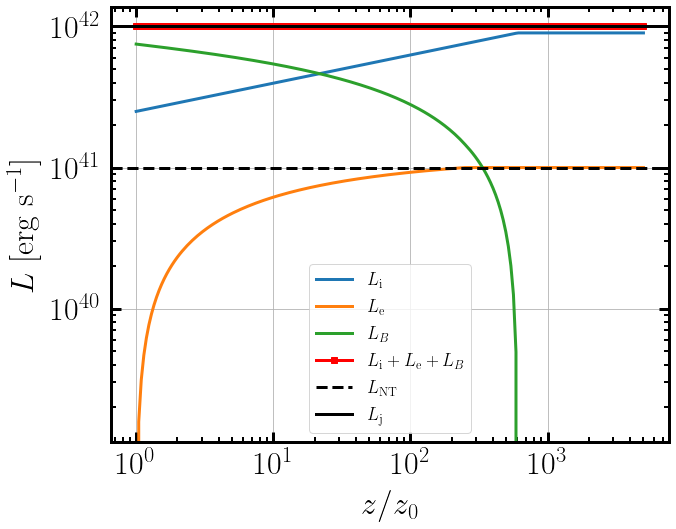

In [21]:
with plt.style.context(('publi')):
    
    fig, ax = plt.subplots()
    ax.set_xlabel(r'$z/z_0$')
    ax.set_ylabel(r'$L ~ [{\rm erg~s}^{-1}]$')
    
    ax.loglog(z_rg/z0_rg, Li(zVec), label=r'$L_{\rm i}$')
    ax.loglog(z_rg/z0_rg, Le_Lph(zVec), label=r'$L_{\rm e}$')
    ax.loglog(z_rg/z0_rg, Lb(zVec), label=r'$L_B$')
    ax.loglog(z_rg/z0_rg, Lb(zVec) + Li(zVec) + Le_Lph(zVec), color='r', marker='s', label=r'$L_{\rm i}+L_{\rm e}+L_B$')
    ax.axhline(Linj, color='k', ls='--', label=r'$L_{\rm NT}$')
    ax.axhline(Ljet, color='k', ls='-', label=r'$L_{\rm j}$')
    ax.legend(fontsize=18)
    
    fig.savefig('Jet_power.pdf', dpi=300)